# Hệ thống Phân tích Cảm xúc TikTok Song ngữ (Tiếng Việt & Tiếng Anh)

- **Nguồn đầu vào linh hoạt:** Hỗ trợ **Link TikTok** (tự tải video/ảnh + crawl comment & reply), **File nguồn cục bộ** (`.csv`, `.xlsx`, `.xls`, `.json`, `.txt`, có thể kèm video/ảnh), hoặc **Thư mục có sẵn** (`data/<post_id>/`).
- **Giai đoạn 1 — AI Đầu vào (`gemma4-e2b-opt`, tùy chọn):** Đọc khung hình có mốc thời gian (`768px`, tự động 2-pass cho slideshow dài) + lời thoại Whisper + caption để trích xuất ngữ cảnh Evidence-First (11 trường).
- **Giai đoạn 2 — Tiền xử lý & Lọc nhiễu (`src/preprocessing/text_cleaner.py`):** Nhận diện ngôn ngữ (`vi` / `en`), lọc bình luận nhiễu (`@tag` bạn bè, tên riêng đơn lẻ qua `underthesea`, URL, seeding, spam quảng cáo, ngôn ngữ khác).
- **Giai đoạn 3 — Lõi ML & Deep Learning (`src/models/classical_ml.py` + `sentiment_engine.py`):**
  - **Tiếng Việt:** `TF-IDF (NB/LR/SVM)` + `Vietnamese Lexicon` + `ViSoBERT` + `PhoBERT` + `PhoBERT Emotion (7 cung bậc)`.
  - **Tiếng Anh:** `TF-IDF (NB/LR/SVM)` + `English Lexicon` + `Twitter-RoBERTa` + `DistilRoBERTa Emotion (7 cung bậc)`.
- **Giai đoạn 4 — AI Đầu ra (`src/models/gemma_auditor.py`, tùy chọn bật/tắt):** `gemma4-e2b-opt` thẩm định kết quả Giai đoạn 3, phát hiện nói mỉa (`sarcasm`) và xuất bộ kết quả tách gọn ra **`outputs/<run_name>/`** (`cleaned_final_results.csv`, `final_results.csv`, `detailed_model_outputs.csv`).

> Lưu ý: Chỉ cần khởi động container Ollama `gemma4-e2b` khi sử dụng Giai đoạn 1 (phân tích video/ảnh) hoặc Giai đoạn 4 (thẩm định bằng AI).

In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from src.pipeline import SentimentPipeline
from src.visualization import plot_sentiment_dashboard
# Nhật anh project
# === TÙY CHỌN GÁN CỨNG (để None nếu muốn notebook hỏi tương tác khi chạy) ===
INPUT_MODE = None            # None (hỏi trực tiếp) | "url" | "file" | "folder"
TIKTOK_URL = ""
COMMENTS_FILE = ""           # Đường dẫn .csv / .xlsx / .xls / .json / .txt (cho chế độ "file")
MEDIA_INPUT = None           # Tùy chọn: đường dẫn video/ảnh/thư mục ảnh kèm theo file nguồn
INPUT_DIR = None             # Đường dẫn thư mục đã tải (vd: "data/7711458816386190614") cho chế độ "folder"
CAPTION = ""                 # Caption bổ sung nếu dùng media cục bộ
TEXT_COLUMN = None           # Tên cột chứa bình luận (None = tự động nhận diện)
RUN_MEDIA_ANALYSIS = True    # True = chạy Giai đoạn 1 nếu có video/ảnh; False = bỏ qua Giai đoạn 1
RUN_AI_AUDIT = None          # None (hỏi trực tiếp) | True (chạy Giai đoạn 4) | False (bỏ qua Giai đoạn 4)

# === CHỌN NGUỒN ĐẦU VÀO ===
if INPUT_MODE is None:
    print("Chọn nguồn dữ liệu đầu vào:")
    print("  1. Link TikTok (tự tải media & crawl comment + reply)")
    print("  2. File nguồn trực tiếp (.csv, .xlsx, .xls, .json, .txt)")
    print("  3. Thư mục đã tải sẵn (vd: data/<post_id>)")
    _choice = input("Nhập lựa chọn [1/2/3, mặc định 1]: ").strip() or "1"
    INPUT_MODE = {"1": "url", "2": "file", "3": "folder"}.get(_choice, "url")

if INPUT_MODE == "url":
    if not TIKTOK_URL:
        TIKTOK_URL = input("Nhập link video/ảnh TikTok: ").strip().strip('"\'')
elif INPUT_MODE == "file":
    if not COMMENTS_FILE:
        COMMENTS_FILE = input("Nhập đường dẫn file bình luận (.csv/.xlsx/.json/.txt): ").strip().strip('"\'')
    if MEDIA_INPUT is None:
        _media_in = input("Đường dẫn video/ảnh kèm theo (Enter để bỏ qua Giai đoạn 1): ").strip().strip('"\'')
        MEDIA_INPUT = _media_in or None
    if MEDIA_INPUT is not None and not CAPTION:
        CAPTION = input("Caption bài đăng (Enter để bỏ qua): ").strip()
elif INPUT_MODE == "folder":
    if not INPUT_DIR:
        INPUT_DIR = input("Nhập đường dẫn thư mục (vd: data/7711458816386190614): ").strip().strip('"\'')
else:
    raise ValueError(f"INPUT_MODE không hợp lệ: {INPUT_MODE} (chọn 'url', 'file', hoặc 'folder').")

# === TÙY CHỌN GIAI ĐOẠN 4 (THẨM ĐỊNH BẰNG AI) ===
if RUN_AI_AUDIT is None:
    _ans = input("Có chạy Giai đoạn 4 (dùng AI Gemma 4 thẩm định kết quả Giai đoạn 3) không? [y/N, mặc định y]: ").strip().lower()
    RUN_AI_AUDIT = True if _ans in {"", "y", "yes", "c", "co", "có", "1"} else False

# === CẤU HÌNH HỆ THỐNG ===
ENABLE_AUDIO = True
AUDIT_LIMIT = None             # None = chấm 100% bình luận hợp lệ
MAX_COMMENTS = 2000            # Số lượng bình luận tối đa cần thu thập (cả comment + reply)
INCLUDE_REPLIES = True         # Thu thập cả bình luận trả lời (reply)
MAX_REPLIES_PER_COMMENT = None # None = lấy toàn bộ reply tới khi chạm MAX_COMMENTS
DEDUPLICATE_STATS = False      # True nếu muốn loại bỏ bình luận copy-paste khỏi tỷ lệ %
DATA_DIR = Path("data")        # Nơi lưu toàn bộ dữ liệu thu thập thô
OUTPUT_DIR = Path("outputs")   # Nơi xuất kết quả cuối cùng sau xử lý

print(f"-> Chế độ đầu vào: {INPUT_MODE} | Giai đoạn 1 (Media AI): {RUN_MEDIA_ANALYSIS} | Giai đoạn 4 (AI Audit): {RUN_AI_AUDIT}")

Chọn nguồn dữ liệu đầu vào:
  1. Link TikTok (tự tải media & crawl comment + reply)
  2. File nguồn trực tiếp (.csv, .xlsx, .xls, .json, .txt)
  3. Thư mục đã tải sẵn (vd: data/<post_id>)
-> Chế độ đầu vào: url | Giai đoạn 1 (Media AI): True | Giai đoạn 4 (AI Audit): False


In [2]:
# === CHẠY TOÀN BỘ PIPELINE ===
if INPUT_MODE == "url" and not TIKTOK_URL:
    raise ValueError("Vui lòng nhập link TikTok vào biến TIKTOK_URL.")
if INPUT_MODE == "file" and not COMMENTS_FILE:
    raise ValueError("Vui lòng nhập đường dẫn file bình luận vào biến COMMENTS_FILE.")
if INPUT_MODE == "folder" and not INPUT_DIR:
    raise ValueError("Vui lòng nhập đường dẫn thư mục vào biến INPUT_DIR.")

pipeline = SentimentPipeline()
report = pipeline.run(
    tiktok_url=TIKTOK_URL if INPUT_MODE == "url" else None,
    input_dir=INPUT_DIR if INPUT_MODE == "folder" else None,
    media_input=MEDIA_INPUT if INPUT_MODE != "url" else None,
    comments_source=COMMENTS_FILE if INPUT_MODE == "file" else None,
    caption=CAPTION,
    enable_audio=ENABLE_AUDIO,
    run_media_analysis=RUN_MEDIA_ANALYSIS,
    text_column=TEXT_COLUMN,
    run_ai_audit=RUN_AI_AUDIT,
    audit_limit=AUDIT_LIMIT,
    max_comments=MAX_COMMENTS,
    include_replies=INCLUDE_REPLIES,
    max_replies_per_comment=MAX_REPLIES_PER_COMMENT,
    deduplicate_stats=DEDUPLICATE_STATS,
    data_dir=DATA_DIR,
    output_dir=OUTPUT_DIR,
)

run_name = report["run_name"]
print(f"-> Kết quả xử lý xuất tại: {OUTPUT_DIR / run_name}")

if report.get("media_analysis"):
    print("\n=== GIAI ĐOẠN 1: NGỮ CẢNH VIDEO / ẢNH (GEMMA 4 E2B) ===")
    print(json.dumps(report["media_analysis"], ensure_ascii=False, indent=2))

[Bước 0] Đang tải video/ảnh & metadata vào data\7711719899852295445...
[Bước 0] Đang thu thập bình luận vào data\7711719899852295445\raw_comments.csv...
Đang mở trình duyệt tới: https://www.tiktok.com/@datquandiem/video/7711719899852295445?is_from_webapp=1&sender_device=pc

[Tạm dừng] Trên cửa sổ trình duyệt vừa mở:
  1. Đóng popup đăng nhập (hoặc đăng nhập nếu TikTok yêu cầu).
  2. Mở phần bình luận (nếu chưa hiện) hoặc hoàn tất xác minh (nếu có).
  Lần cuộn 1/40: thu được 83 bình luận (40 chính, 43 reply)
  Lần cuộn 2/40: thu được 132 bình luận (70 chính, 62 reply)
  Lần cuộn 3/40: thu được 175 bình luận (97 chính, 78 reply)
  Lần cuộn 4/40: thu được 202 bình luận (110 chính, 92 reply)
Đã đạt giới hạn 200 bình luận.
[Giai đoạn 1] Gemma 4 E2B đang phân tích ngữ cảnh video/ảnh...
[Giai đoạn 2] Lọc nhiễu, nhận diện ngôn ngữ (VI/EN) & tách từ (200 bình luận)...
  -> Hợp lệ: 197 | Đã lọc nhiễu: 3
[Giai đoạn 3] Đang chạy ML cổ điển, Lexicon, Deep Learning (VI/EN) & Hybrid...


Model phobert-emotion: 100%|██████████| 7/7 [00:13<00:00,  1.86s/batch]


[Giai đoạn 4] Đã bỏ qua thẩm định AI theo tùy chọn người dùng (run_ai_audit=False).
-> Kết quả xử lý xuất tại: outputs\7711719899852295445

=== GIAI ĐOẠN 1: NGỮ CẢNH VIDEO / ẢNH (GEMMA 4 E2B) ===
{
  "media_type": "video",
  "source_paths": [
    "data\\7711719899852295445\\video.mp4"
  ],
  "num_frames_used": 8,
  "has_audio": true,
  "caption": "Làm ơn hãy cho Việt Nam thời gian phát triển #bankerthichcode #chinhtri #lichsu #Capcut",
  "transcript": "[00:00-00:04] Tại sao các cường quốc tư bản mạnh nhất thế giới này, ví dụ như Mỹ, Châu Âu, Nhật Bản\n[00:04-00:08] nó lại sở hiểu những công nghệ lõi mạnh mẽ nhất thế giới này?\n[00:08-00:12] Đọc quyền luôn và nưa nước họ trở thành một bá chủ về công nghệ.\n[00:12-00:15] Trong khi đó, nhìn sang Việt Nam thì Việt Nam trả có một công nghệ lõi nào\n[00:15-00:18] để có thể sánh vai với các cường quốc như vậy.\n[00:18-00:21] Hãy vảnh tay lên và nghe hết cái video clip này đi.\n[00:21-00:24] Các bạn sẽ được mở mang và sẽ thấy chân trọng cuộc s

In [3]:
# === XEM KẾT QUẢ TÁCH BIỆT COMMENT SẠCH, CHI TIẾT MÔ HÌNH & COMMENT NHIỄU ===
print("=== THỐNG KÊ LỌC NHIỄU & NGÔN NGỮ ===")
print(json.dumps(report["noise_filter_summary"], ensure_ascii=False, indent=2))
if report.get("sentiment_summary"):
    print("Phân bố ngôn ngữ hợp lệ:", report["sentiment_summary"]["language_counts"])

exported = report.get("exported_files", {})
if "cleaned_final_results_csv" in exported:
    df_summary = pd.read_csv(exported["cleaned_final_results_csv"], encoding="utf-8-sig")
    print(f"\nBảng tóm gọn các cột chính (cleaned_final_results.csv — {len(df_summary.columns)} cột): {len(df_summary)} dòng")
    display(df_summary.head(20))

if "final_results_csv" in exported:
    df_clean = pd.read_csv(exported["final_results_csv"], encoding="utf-8-sig")
    df_clean.columns = [c.split("\n", 1)[0] for c in df_clean.columns]
    preview_cols = [
        c for c in [
            "is_reply", "language", "original_text", "polarity_label", "score_5", "score_10",
            "emotion_vi", "gemma_polarity", "gemma_emotion_vi", "gemma_score_5",
            "gemma_is_sarcasm", "gemma_reason"
        ] if c in df_clean.columns
    ]
    print(f"\nBảng thuộc tính hữu ích (final_results.csv — {len(df_clean.columns)} cột): {len(df_clean)} dòng")
    display(df_clean[preview_cols].head(20))

if "detailed_model_outputs_csv" in exported:
    df_detail = pd.read_csv(exported["detailed_model_outputs_csv"], encoding="utf-8-sig")
    df_detail.columns = [c.split("\n", 1)[0] for c in df_detail.columns]
    print(f"\nBảng chi tiết mô hình & xác suất (detailed_model_outputs.csv — {len(df_detail.columns)} cột): {len(df_detail)} dòng")
    display(df_detail.head(10))

if "filtered_noise_csv" in exported:
    df_noise = pd.read_csv(exported["filtered_noise_csv"], encoding="utf-8-sig")
    print(f"\nSố comment bị lọc nhiễu (filtered_noise.csv): {len(df_noise)}")
    display(df_noise.head(20))

=== THỐNG KÊ LỌC NHIỄU & NGÔN NGỮ ===
{
  "total_raw_comments": 200,
  "valid_comments": 197,
  "filtered_noise_count": 3,
  "duplicate_valid_count": 1,
  "filter_reasons": {
    "FILTERED_UNSUPPORTED_LANG": 3
  }
}
Phân bố ngôn ngữ hợp lệ: {'vi': 197, 'en': 0}

Bảng tóm gọn các cột chính (cleaned_final_results.csv — 10 cột): 197 dòng


,username\n(tên tài khoản),is_reply\n(là bình luận trả lời),likes\n(lượt thích),created_at\n(thời gian đăng),language\n(ngôn ngữ),original_text\n(nội dung gốc),polarity_vi\n(cực tính hệ thống),score_5\n(điểm thang 1-5),score_10\n(điểm thang 0-10),emotion_vi\n(cảm xúc 7 cung bậc)
0,vn.qu.hng.ti.p.lm,False,165,2026-11-24 20:50:32,vi,Cách đây gần 20 năm trên diễn đàn hoangsa tôi ...,Tích cực,4,7.64,Trung tính / Khác
1,allehap28,False,80,2026-11-24 20:54:13,vi,trước khi nhật bản nó đi xâm lược thì bản thân...,Tiêu cực,1,0.82,Chán ghét / Khó chịu
2,datquandiem,True,79,2026-11-24 21:17:55,vi,Trọng nhân tài bằng gì? Bằng tiền! Tiền ở đâu ...,Trung tính,3,4.48,Trung tính / Khác
3,haylachinhminh80,False,61,2026-11-24 20:39:58,vi,có lần nghe tướng phạm văn Trà nói: suốt thế k...,Tích cực,4,6.25,Vui vẻ / Hài lòng
4,datquandiem,True,56,2026-11-24 21:54:16,vi,"Vãi cả ông, 1600 Nhật nó trùm xuất khẩu bạc đồ...",Tiêu cực,1,1.09,Chán ghét / Khó chịu
5,nhacnguyen669,False,50,2026-11-24 23:36:50,vi,Việt Nam có công nghệ lõi là phạt giao thông.,Trung tính,3,4.32,Trung tính / Khác
6,haibeo2211,False,48,2026-11-24 19:59:19,vi,Ko hiểu cái ông nào phát minh ra cái Công Nghệ...,Tiêu cực,1,1.19,Lo lắng / Sợ hãi
7,datquandiem,True,39,2026-11-24 21:46:56,vi,"Nga năm 1917 rất nghèo, không xuất phát điểm t...",Trung tính,3,4.43,Trung tính / Khác
8,_.memoire._,False,39,2026-11-24 23:39:46,vi,Một thế hệ 9x như mình thấy rõ ràng đất nước p...,Trung tính,3,4.05,Chán ghét / Khó chịu
9,datquandiem,True,34,2026-11-25 08:24:31,vi,Nói như m Mỹ có công nghệ lõi chi phí y tế,Trung tính,3,4.62,Vui vẻ / Hài lòng



Bảng thuộc tính hữu ích (final_results.csv — 18 cột): 197 dòng


,is_reply,language,original_text,polarity_label,score_5,score_10,emotion_vi
0,False,vi,Việt Nam có công nghệ lõi là phạt giao thông.,NEU,3,4.32,Trung tính / Khác
1,True,vi,Nói như m Mỹ có công nghệ lõi chi phí y tế,NEU,3,4.62,Vui vẻ / Hài lòng
2,False,vi,Họ trọng nhân tài,POS,5,8.38,Vui vẻ / Hài lòng
3,True,vi,Trọng nhân tài bằng gì? Bằng tiền! Tiền ở đâu ...,NEU,3,4.48,Trung tính / Khác
4,False,vi,Tóm lại công nghệ lõi là từ xâm lược à bác,NEG,1,1.46,Chán ghét / Khó chịu
5,False,vi,không có Nga là thiếu sót.,NEG,1,1.48,Chán ghét / Khó chịu
6,True,vi,"Nga năm 1917 rất nghèo, không xuất phát điểm t...",NEU,3,4.43,Trung tính / Khác
7,False,vi,Đáy xã hội nghe nặng nề quá,NEG,1,0.10,Chán ghét / Khó chịu
8,False,vi,Công nghê lõi là phạt phạt và luật rừng,NEG,2,3.04,Trung tính / Khác
9,False,vi,"Đọc bình luận mà đau lòng, dân nước mình cứ đi...",NEG,1,0.16,Chán ghét / Khó chịu



Bảng chi tiết mô hình & xác suất (detailed_model_outputs.csv — 20 cột): 197 dòng


,comment_id,username,original_text,nickname,segmented_text,is_duplicate,has_sarcasm_signal,needs_audit,polarity_score,score_POS,score_NEG,score_NEU,emotion_label,pred_nb,pred_lr,pred_svm,pred_lexicon,pred_visobert,pred_dl_primary,emotion_ml_label
0,7711777834070590209,nhacnguyen669,Việt Nam có công nghệ lõi là phạt giao thông.,Bingling,Việt_Nam có công_nghệ lõi là phạt giao_thông .,False,False,True,-0.1362,0.1580,0.3398,0.5022,Other,NEG,NEG,NEG,NEU,NEG,NEU,Disgust
1,7711913705274278708,datquandiem,Nói như m Mỹ có công nghệ lõi chi phí y tế,Đạt quan điểm,Nói như m Mỹ có công_nghệ lõi chi_phí y_tế,False,False,True,-0.0766,0.1349,0.2970,0.5681,Enjoyment,NEU,NEU,NEU,NEU,NEG,NEU,Disgust
2,7711735442383684353,kien38525,Họ trọng nhân tài,kien,Họ trọng_nhân_tài,False,False,False,0.6770,0.7326,0.1076,0.1598,Enjoyment,NEG,POS,POS,NEU,POS,POS,Other
3,7711742028246680341,datquandiem,Trọng nhân tài bằng gì? Bằng tiền! Tiền ở đâu ...,Đạt quan điểm,Trọng_nhân_tài bằng gì ?_Bằng tiền !_Tiền ở đâ...,False,False,True,-0.1035,0.1707,0.3105,0.5188,Other,NEG,NEU,NEU,NEU,NEG,NEU,Disgust
4,7711921391762899720,mellliboy,Tóm lại công nghệ lõi là từ xâm lược à bác,Mellliboy,Tóm_lại công_nghệ lõi là từ xâm_lược à bác,False,False,False,-0.7081,0.0444,0.6735,0.2820,Disgust,NEU,NEU,NEU,NEU,NEG,NEG,Other
5,7711734148495328008,alo_dinh,không có Nga là thiếu sót.,Nguyên Alo,không có Nga là thiếu_sót .,False,False,True,-0.7042,0.0299,0.6653,0.3049,Disgust,NEG,NEG,NEG,NEU,NEU,NEG,Disgust
6,7711749532593160981,datquandiem,"Nga năm 1917 rất nghèo, không xuất phát điểm t...",Đạt quan điểm,"Nga năm 1917 rất nghèo , không xuất_phát_điểm ...",False,False,True,-0.1136,0.2240,0.3668,0.4092,Other,NEG,POS,POS,NEU,NEU,NEG,Other
7,7711946663783875336,user73807464,Đáy xã hội nghe nặng nề quá,CDH duc huy,Đáy xã_hội nghe nặng_nề quá,False,False,False,-0.9803,0.0280,0.9325,0.0395,Disgust,NEG,NEG,NEG,NEG,NEG,NEG,Disgust
8,7711938400941982470,baokhanh201,Công nghê lõi là phạt phạt và luật rừng,Bảo Khánh,Công_nghê lõi là phạt phạt và luật rừng,False,False,True,-0.3918,0.2409,0.6327,0.1264,Other,NEG,NEG,NEG,NEU,POS,NEG,Disgust
9,7711920261558108948,bacxiuiuu,"Đọc bình luận mà đau lòng, dân nước mình cứ đi...",Manifest tháng 11 có COE 🙏,"Đọc bình_luận mà đau_lòng , dân nước mình cứ đ...",False,False,False,-0.9678,0.0326,0.9209,0.0465,Disgust,NEG,NEG,NEG,NEG,NEG,NEG,Sadness



Số comment bị lọc nhiễu (filtered_noise.csv): 3


,comment_id,username,nickname,likes,language,original_text,cleaned_text,filter_reason
0,7711944043438211848,sn733125,SN,0,other,主题是什么？,主题是什么？,FILTERED_UNSUPPORTED_LANG
1,7711750892836815629,bellharris6,ℳ๓₯缈义`,0,other,那是代加工厂，没有光刻机和光刻胶这些东西就没有办法，说白了上游被别人掌握,那是代加工厂，没有光刻机和光刻胶这些东西就没有办法，说白了上游被别人掌握,FILTERED_UNSUPPORTED_LANG
2,7711756758222177037,bellharris6,ℳ๓₯缈义`,0,other,你根本不懂什么叫上游技术，把控核心才能叫上游,你根本不懂什么叫上游技术，把控核心才能叫上游,FILTERED_UNSUPPORTED_LANG


In [4]:
# === SO SÁNH CÁC MÔ HÌNH ML CỔ ĐIỂN VS DEEP LEARNING VS HYBRID ===
comp = report.get("model_comparison", {})
if comp.get("polarity_models"):
    print("=== BẢNG SO SÁNH MÔ HÌNH POLARITY ===")
    df_pol_comp = pd.DataFrame(comp["polarity_models"])
    display(df_pol_comp.dropna(axis=1, how="all"))

if comp.get("emotion_models"):
    print("\n=== BẢNG SO SÁNH MÔ HÌNH 7 CẢM XÚC ===")
    df_emo_comp = pd.DataFrame(comp["emotion_models"])
    display(df_emo_comp.dropna(axis=1, how="all"))

if report.get("ai_audit_verdict"):
    print("\n=== KẾT LUẬN THẨM ĐỊNH ĐẦU RA (GEMMA 4 E2B) ===")
    print(json.dumps(report["ai_audit_verdict"], ensure_ascii=False, indent=2))
else:
    print("\n[Giai đoạn 4] Đã bỏ qua thẩm định AI theo tùy chọn người dùng.")

if report.get("keywords_tfidf"):
    print("\n=== TỪ KHÓA NỔI BẬT (TF-IDF) ===")
    print(json.dumps(report["keywords_tfidf"], ensure_ascii=False, indent=2))

=== BẢNG SO SÁNH MÔ HÌNH POLARITY ===


,model,family,total_comments,pos_count,neu_count,neg_count,pos_pct,neu_pct,neg_pct,inference_time_sec
0,TF-IDF + Naive Bayes,Classical ML,197,35,56,106,17.77,28.43,53.81,0.068
1,TF-IDF + Logistic Regression,Classical ML,197,34,87,76,17.26,44.16,38.58,0.068
2,TF-IDF + Linear SVM,Classical ML,197,45,45,107,22.84,22.84,54.31,0.068
3,Bilingual Lexicon + Rules,Rule-based NLP,197,29,159,9,14.72,80.71,4.57,0.002
4,"ViSoBERT (5CD-AI, VI)",Deep Learning,197,83,20,94,42.13,10.15,47.72,17.640
5,PhoBERT + underthesea (wonrax),Deep Learning,197,37,83,77,18.78,42.13,39.09,15.500
6,Hybrid Ensemble (Hệ thống chính),Hybrid ML + DL,197,41,78,78,20.81,39.59,39.59,NaN



=== BẢNG SO SÁNH MÔ HÌNH 7 CẢM XÚC ===


,model,family,inference_time_sec
0,TF-IDF + Logistic Regression (Emotion),Classical ML,0.026
1,PhoBERT Emotion (visolex/UIT-VSMEC),Deep Learning,14.681



[Giai đoạn 4] Đã bỏ qua thẩm định AI theo tùy chọn người dùng.

=== TỪ KHÓA NỔI BẬT (TF-IDF) ===
{
  "overall": [
    {
      "keyword": "có",
      "tfidf_score": 0.0776
    },
    {
      "keyword": "công nghệ",
      "tfidf_score": 0.0647
    },
    {
      "keyword": "lõi",
      "tfidf_score": 0.0409
    },
    {
      "keyword": "nói",
      "tfidf_score": 0.039
    },
    {
      "keyword": "công nghệ lõi",
      "tfidf_score": 0.0378
    },
    {
      "keyword": "vn",
      "tfidf_score": 0.0346
    },
    {
      "keyword": "nước",
      "tfidf_score": 0.0341
    },
    {
      "keyword": "chuẩn",
      "tfidf_score": 0.0279
    },
    {
      "keyword": "có công nghệ",
      "tfidf_score": 0.0258
    },
    {
      "keyword": "nền",
      "tfidf_score": 0.025
    }
  ],
  "positive": [
    {
      "keyword": "chuẩn",
      "tfidf_score": 0.1075
    },
    {
      "keyword": "hay",
      "tfidf_score": 0.0564
    },
    {
      "keyword": "nói",
      "tfidf_score": 0.056
  

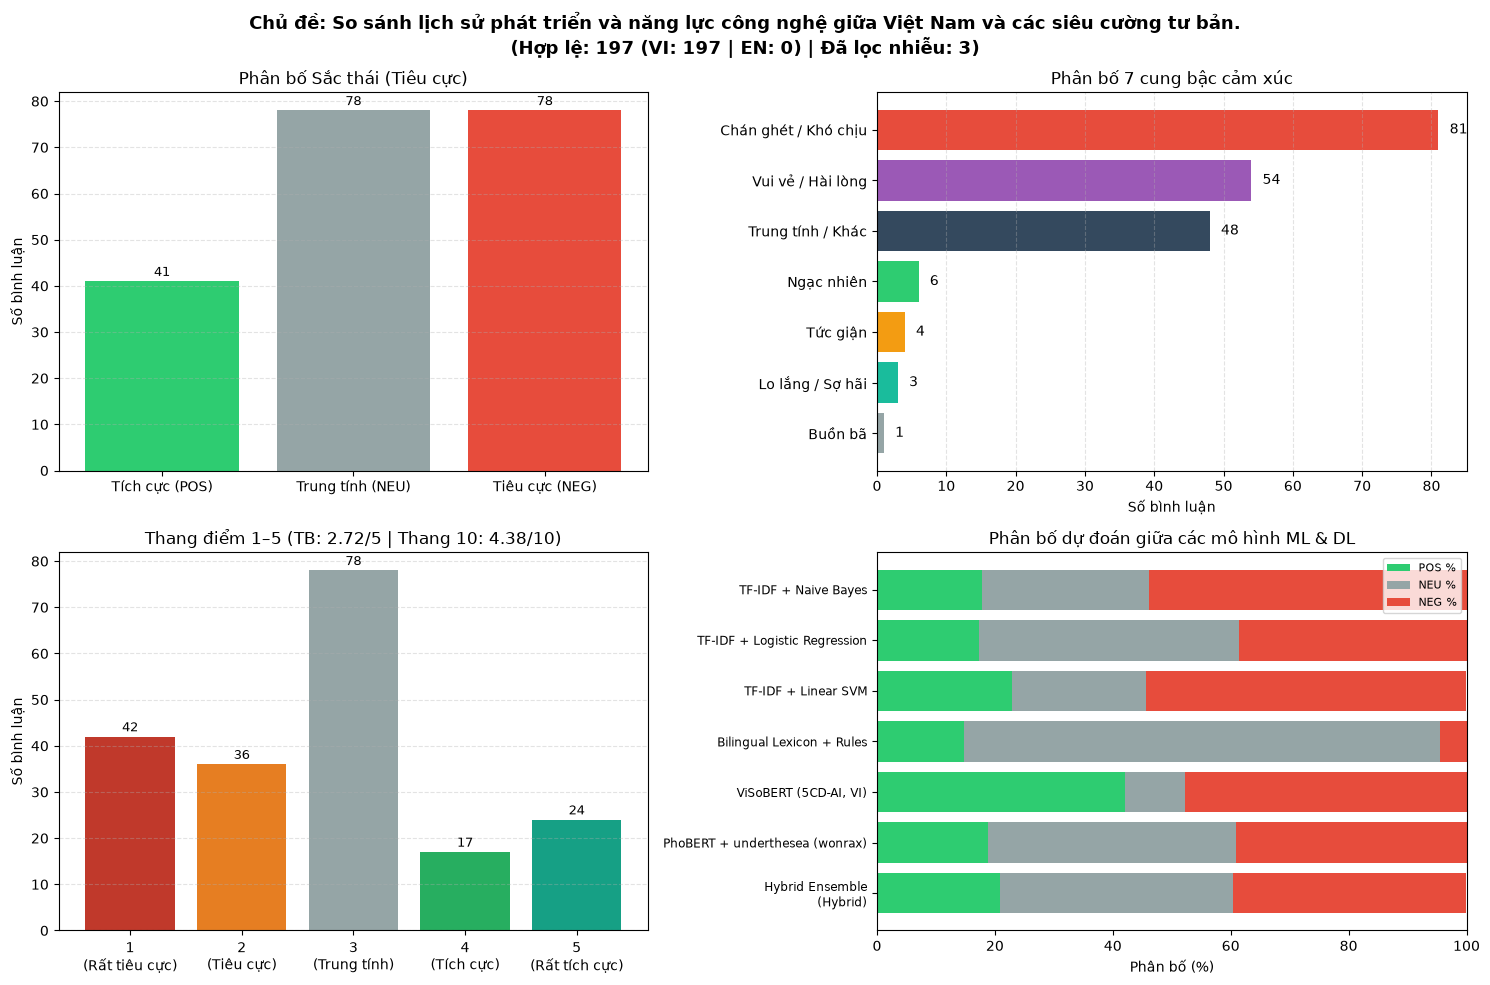

In [5]:
# === DASHBOARD TRỰC QUAN HÓA ===
summary = report.get("sentiment_summary") or {}
if summary.get("total_valid_comments", 0) > 0:
    exported = report.get("exported_files", {})
    chart_path = exported.get("dashboard_png") or (OUTPUT_DIR / report["run_name"] / "dashboard.png")
    fig = plot_sentiment_dashboard(report, save_path=chart_path)
    plt.show()
else:
    print("Không có bình luận hợp lệ để vẽ dashboard.")